# Hotspots: noise calls by block

**A8.** Are noise complaints concentrated in a few blocks, and do the same blocks stay hotspots over time?

**Inputs:** `data/processed/calls_2021_2025.csv.gz`, `data/processed/address_sectors.csv`

**Outputs:** `figures/05_a8_concentration.png`, `figures/05_a8_top_blocks_by_year.png`, `results/05_a8_block_counts.csv`, `results/05_a8_concentration.csv`, `results/05_a8_top_overlap.csv`, `results/05_a8_checks.csv`

In [1]:
# Loaders, hotspot helpers, plot style, and project settings
import matplotlib.pyplot as plt
import pandas as pd

from bpdtools.config import HEADQUARTERS_ADDRESS
from bpdtools.hotspots import block_counts, top_share, yearly_top_overlap
from bpdtools.load import load_calls
from bpdtools.paths import repo_path
from bpdtools.plots import HEATMAP_CMAP, PALETTE, set_plot_style
from bpdtools.sectors import normalize_block_address

set_plot_style()

# Figures and result tables go to fixed folders at the repository root
figures = repo_path("figures")
results = repo_path("results")
figures.mkdir(exist_ok=True)
results.mkdir(exist_ok=True)

# Shares of the blocks whose share of the calls the concentration table gives
TOP_FRACTIONS = (0.01, 0.05, 0.10)

# Number of top blocks compared from year to year; the other two sizes check
# that the result does not depend on this one cutoff
TOP_N = 20
CHECK_TOP_NS = (10, 50)

## Noise calls

Noise calls are the calls for service of the noise call types in `bpdtools.config`, 2021–2025. Calls for service carry a block address, such as "2700 CHANNING WAY", and no map point.

In [2]:
# Noise calls of 2021-2025, with their local time and block address
calls = load_calls()
noise = calls.loc[calls["call_group"].eq("noise")]

# Checks: the number of calls, their years, and addresses that are missing
noise_years = noise["local_time"].dt.year
pd.Series(
    {
        "noise calls": len(noise),
        "first year": int(noise_years.min()),
        "last year": int(noise_years.max()),
        "calls without a block address": int(noise["Block Address"].isna().sum()),
    },
    name="value",
)

noise calls                      12693
first year                        2021
last year                         2025
calls without a block address        0
Name: value, dtype: int64

## Calls per block

`block_counts` matches addresses the same way as the sector lookup, so one block written in different ways counts once. An intersection ("A ST & B ST") is its own location.

The police headquarters, 2100 Martin Luther King Jr Way, appears as a block. A call that is logged at the station's address may not have happened there, so the headquarters block is flagged and the checks below leave it out.

In [3]:
# Noise calls per block, busiest first
blocks = block_counts(noise)
blocks.to_csv(results / "05_a8_block_counts.csv")

# Flags for the checks: the headquarters block and intersections
is_headquarters = blocks.index == HEADQUARTERS_ADDRESS
is_intersection = blocks.index.str.contains(" & ")
headquarters_rank = int(blocks.index.get_loc(HEADQUARTERS_ADDRESS)) + 1

pd.Series(
    {
        "blocks with a noise call": len(blocks),
        "noise calls on a block": int(blocks.sum()),
        "headquarters calls": int(blocks[is_headquarters].sum()),
        "headquarters rank": headquarters_rank,
        "intersections": int(is_intersection.sum()),
        "calls at intersections": int(blocks[is_intersection].sum()),
    },
    name="value",
)

blocks with a noise call     1626
noise calls on a block      12693
headquarters calls            185
headquarters rank               5
intersections                 588
calls at intersections       1936
Name: value, dtype: int64

In [4]:
# The ten busiest blocks
blocks.head(10).to_frame()

,count
block,
2700 CHANNING WAY,215
2500 DURANT AVE,191
2400 PIEDMONT AVE,189
2400 WARRING ST,188
2100 MARTIN LUTHER KING JR WAY,185
2700 BANCROFT WAY,176
1000 UNIVERSITY AVE,175
2000 SHATTUCK AVE,137
2600 COLLEGE AVE,135


## How concentrated are noise calls?

The share of all noise calls that falls in the busiest 1%, 5%, and 10% of blocks. If calls were spread evenly, the busiest 5% of blocks would hold 5% of the calls.

In [5]:
# Share of all calls in the busiest blocks
concentration = top_share(blocks, TOP_FRACTIONS)
concentration.to_csv(results / "05_a8_concentration.csv", index=False)
concentration.round(3)

,fraction,n_blocks,n_calls,share
0,0.01,16,2403,0.189
1,0.05,81,5618,0.443
2,0.10,163,7544,0.594


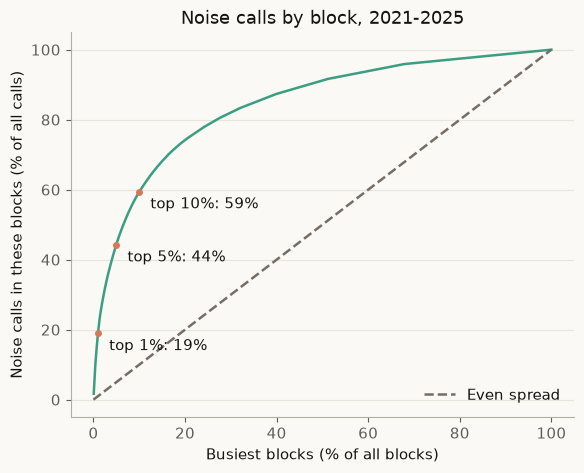

In [6]:
# Cumulative share of the calls against the share of the blocks, busiest
# block first; the dashed line is an even spread of the calls
block_share = pd.Series(range(1, len(blocks) + 1)) / len(blocks)
call_share = blocks.cumsum().to_numpy() / blocks.sum()

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(block_share * 100, call_share * 100, color=PALETTE[0])
ax.plot([0, 100], [0, 100], linestyle="--", color=PALETTE[5], label="Even spread")
for row in concentration.itertuples():
    ax.plot(row.fraction * 100, row.share * 100, "o", color=PALETTE[1])
    ax.annotate(
        f"top {row.fraction:.0%}: {row.share:.0%}",
        (row.fraction * 100, row.share * 100),
        xytext=(8, -12),
        textcoords="offset points",
    )
ax.set_xlabel("Busiest blocks (% of all blocks)")
ax.set_ylabel("Noise calls in these blocks (% of all calls)")
ax.set_title("Noise calls by block, 2021-2025")
ax.legend(loc="lower right")
fig.savefig(figures / "05_a8_concentration.png")

## Do the same blocks stay hotspots?

Each year's top 20 blocks are compared with the next year's. A block that ties with the 20th block also counts as a top block, so a year can have a few more than 20. The top 10 and top 50 check that the result does not depend on the cutoff.

In [7]:
# Top blocks of each year compared with the next year, for three cutoffs
overlap_tables = []
every_year = {}
for n_top in (TOP_N, *CHECK_TOP_NS):
    pairs, every_year[n_top] = yearly_top_overlap(noise, "local_time", n_top)
    overlap_tables.append(pairs.assign(cutoff=n_top))
overlap = pd.concat(overlap_tables, ignore_index=True)
overlap["share_shared"] = (overlap["n_shared"] / overlap["n_top"]).round(3)
overlap.to_csv(results / "05_a8_top_overlap.csv", index=False)
overlap

,year,next_year,n_top,n_top_next,n_shared,cutoff,share_shared
0,2021,2022,20,22,14,20,0.700
1,2022,2023,22,20,14,20,0.636
2,2023,2024,20,24,12,20,0.600
3,2024,2025,24,20,13,20,0.542
4,2021,2022,10,10,6,10,0.600
5,2022,2023,10,10,4,10,0.400
6,2023,2024,10,11,3,10,0.300
7,2024,2025,11,11,6,10,0.545
8,2021,2022,51,56,32,50,0.627
9,2022,2023,56,54,30,50,0.536


In [8]:
# Beat sector of each block in the top 20 every year, from the address
# lookup that the calendar and location analyses also use
lookup = pd.read_csv(repo_path("data", "processed", "address_sectors.csv"), dtype=str)
lookup.set_index("block_key").reindex(every_year[TOP_N])[["Sector", "sector_status"]]

,Sector,sector_status
block_key,,
2100 MARTIN LUTHER KING JR WAY,5,assigned
2400 PIEDMONT AVE,7,assigned
2400 WARRING ST,7,assigned
2500 BENVENUE AVE,7,assigned
2500 DURANT AVE,6,assigned
2700 BANCROFT WAY,NaN,outside
2700 CHANNING WAY,7,assigned


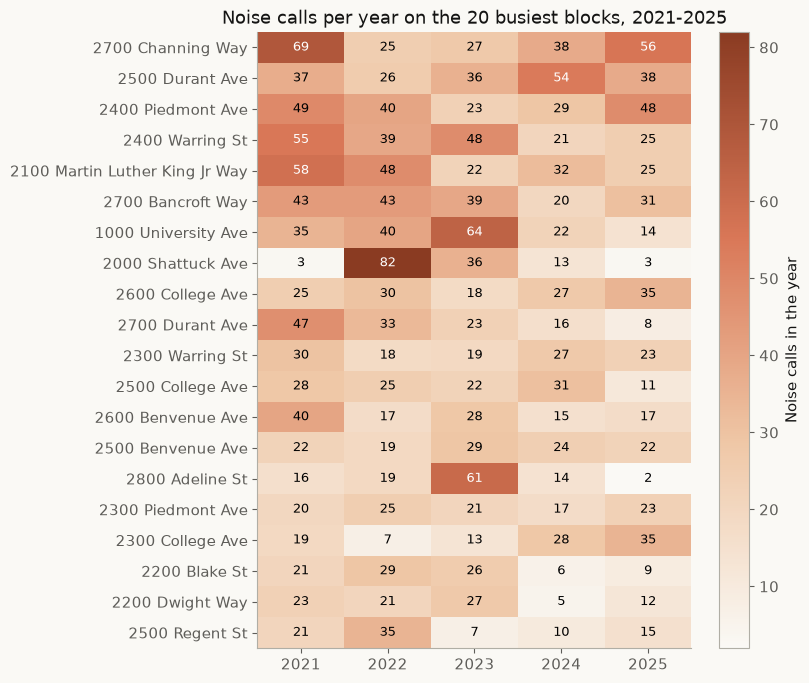

In [9]:
# Calls per year of the 20 busiest blocks of 2021-2025
top_blocks = blocks.index[:TOP_N]
by_year = pd.DataFrame(
    {
        year: block_counts(noise.loc[noise_years.eq(year)]).reindex(
            top_blocks, fill_value=0
        )
        for year in sorted(noise_years.unique())
    }
)

fig, ax = plt.subplots(figsize=(7, 8))
image = ax.imshow(by_year, cmap=HEATMAP_CMAP, aspect="auto")
ax.set_xticks(range(len(by_year.columns)), by_year.columns)
ax.set_yticks(range(len(by_year.index)), [name.title() for name in by_year.index])
# White numbers on the darkest cells, dark numbers elsewhere
dark_cutoff = 0.6 * by_year.to_numpy().max()
for (row, column), value in pd.DataFrame(by_year.to_numpy()).stack().items():
    color = "white" if value > dark_cutoff else "black"
    ax.text(column, row, value, ha="center", va="center", fontsize=9, color=color)
ax.grid(False)
ax.set_title(f"Noise calls per year on the {TOP_N} busiest blocks, 2021-2025")
fig.colorbar(image, ax=ax, label="Noise calls in the year")
fig.savefig(figures / "05_a8_top_blocks_by_year.png")

## Checks

Both measures again without the headquarters block, without intersections, and without both.

In [10]:
# Address keys of the calls, the same keys that block_counts uses
noise_keys = normalize_block_address(noise["Block Address"])
at_headquarters = noise_keys.eq(HEADQUARTERS_ADDRESS)
at_intersection = noise_keys.str.contains(" & ", regex=False)

# Concentration and stability for each way of leaving blocks out
noise_versions = {
    "all blocks": noise,
    "without headquarters": noise.loc[~at_headquarters],
    "without intersections": noise.loc[~at_intersection],
    "without both": noise.loc[~at_headquarters & ~at_intersection],
}
rows = []
for version, events in noise_versions.items():
    shares = top_share(block_counts(events), TOP_FRACTIONS)
    pairs, on_top = yearly_top_overlap(events, "local_time", TOP_N)
    rows.append(
        {
            "version": version,
            "noise calls": len(events),
            "top 1% share": shares["share"].iloc[0],
            "top 5% share": shares["share"].iloc[1],
            "top 10% share": shares["share"].iloc[2],
            f"mean top {TOP_N} shared": pairs["n_shared"].mean(),
            f"top {TOP_N} every year": len(on_top),
        }
    )
checks = pd.DataFrame(rows).round(3)
checks.to_csv(results / "05_a8_checks.csv", index=False)
checks

,version,noise calls,top 1% share,top 5% share,top 10% share,mean top 20 shared,top 20 every year
0,all blocks,12693,0.189,0.443,0.594,13.25,7
1,without headquarters,12508,0.185,0.437,0.590,13.00,7
2,without intersections,10757,0.160,0.420,0.577,13.50,7
3,without both,10572,0.156,0.413,0.572,12.75,7


## Findings

- **Noise calls are concentrated in a few blocks.** The 12,693 noise calls of 2021–2025 fall on 1,626 blocks and intersections. The busiest 1% of blocks (16) hold 19% of the calls, the busiest 5% (81) hold 44%, and the busiest 10% (163) hold 59%.
- **Many hotspots stay hotspots.** From one year to the next, 54% to 70% of the top 20 blocks stay in the top 20 (50% to 63% for the top 50, and 30% to 60% for the smaller top 10). Seven blocks are in the top 20 in all five years. Apart from the police headquarters, five of them are in Southside (beats 6 and 7), and 2700 Bancroft Way is on the edge of campus, outside the beat map.
- **Some blocks spike for one year.** 2000 Shattuck Ave had 82 noise calls in 2022 but 3 in 2021 and in 2025, and 2800 Adeline St had 61 in 2023.
- **The checks agree.** Without the headquarters block, without intersections, or without both, the busiest 5% of blocks still hold 41% to 44% of the calls, and seven blocks still stay in the top 20 every year.

## Limitations

- A block address covers a whole block, and an intersection covers a corner, so a hotspot is a stretch of street, not one building.
- A call is a report. One resident can call about the same party many times, so a hotspot means many reports, not necessarily many noisy events.
- The headquarters block probably holds calls logged at the station's address; the checks leave it out.
- The numbers describe 2021–2025 only. A block with no calls in a year means no records in the dataset that year, not a quiet year.